# Colony Segmentation in camiira
This notebook demonstrates how to use camiira's colony segmentation (detection) pipeline using Python functions and classes directly (not CLI).

In [1]:
from pathlib import Path

import numpy as np
import polars as pl
import cv2 as cv
import matplotlib.pyplot as plt

from camiira.detector import CAMIIColonyDetector
from camiira.detect_colonies import (
    detect_colony,
    colony_qc,
    correct_image,
    _modify_output_object_colony_detection,
    _calc_contour_channel_mean_std,
)
from camiira.utils import read_config, add_contours

## 1. Load Images and Configuration

We'll use the same plate as in the alignment example: **ABYPS158** at time point **max** (day 5).

In practice, **trans-illumination is the primary modality** for segmentation (superior contrast, robust to color variations), while epi-illumination provides secondary color/texture features after segmentation.

camiira uses two types of illumination for imaging bacterial colonies:

**Epi-Illumination with White Light**: Light source and camera both above the plate. Colonies appear with their **natural colors** and textures for phenotyping.

**Transmitted (Trans) Illumination with Red Light**: Light source below the plate, camera above. Colonies appear as **dark regions** (shadows) on a bright background, providing high contrast for edge detection.

In [2]:
# Data paths
base_dir = Path("/mnt/c/aws_data/data/camii/202401_darpa_arcadia_arl_boneyard")
plate = "ABYPS158"
time_point = "max"  # corresponds to d5

# Image paths (note: 'max' time point corresponds to d5 images)
trans_image_path = base_dir / "rgb" / "red_grayscale" / f"{plate}_d5.png"
epi_image_path = base_dir / "rgb" / "white_rgb" / f"{plate}_d5.png"

# Load configuration (contains hyperparameters)
config_path = Path("/home/whatever60/dev/camiira/test_data/configs/configure.yaml")
config = read_config(config_path)

print(f"Trans image: {trans_image_path}")
print(f"Epi image: {epi_image_path}")
print(f"\nKey hyperparameters:")
for key in [
    "bg_threshold_block_size",
    "bg_threshold_offset",
    "canny_upper_percentile",
    "min_size",
    "max_size",
    "min_circularity",
]:
    print(f"  {key}: {config[key]}")

Trans image: /mnt/c/aws_data/data/camii/202401_darpa_arcadia_arl_boneyard/rgb/red_grayscale/ABYPS158_d5.png
Epi image: /mnt/c/aws_data/data/camii/202401_darpa_arcadia_arl_boneyard/rgb/white_rgb/ABYPS158_d5.png

Key hyperparameters:
  bg_threshold_block_size: 501
  bg_threshold_offset: 18
  canny_upper_percentile: 80
  min_size: 400
  max_size: 2000000
  min_circularity: 0.2


## 2. Visualize Raw Images

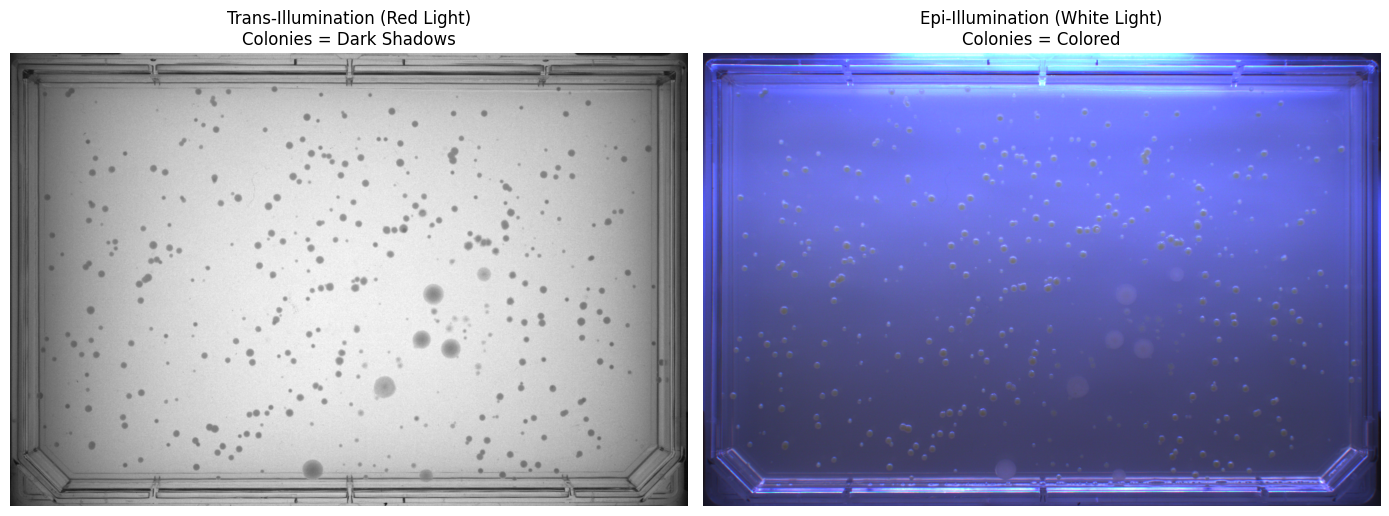

Trans image shape: (1296, 1938) (grayscale)
Epi image shape: (1296, 1938, 3) (RGB)


In [3]:
# Load raw images
image_trans_raw = cv.imread(str(trans_image_path), cv.IMREAD_GRAYSCALE).astype(
    np.float32
)
image_epi_raw = cv.imread(str(epi_image_path), cv.IMREAD_COLOR).astype(np.float32)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Trans-illumination (colonies appear dark)
axes[0].imshow(image_trans_raw, cmap="gray")
axes[0].set_title("Trans-Illumination (Red Light)\nColonies = Dark Shadows")
axes[0].axis("off")

# Epi-illumination (colonies with natural colors)
axes[1].imshow(cv.cvtColor(image_epi_raw.astype(np.uint8), cv.COLOR_BGR2RGB))
axes[1].set_title("Epi-Illumination (White Light)\nColonies = Colored")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Trans image shape: {image_trans_raw.shape} (grayscale)")
print(f"Epi image shape: {image_epi_raw.shape} (RGB)")

## 3. Colony Detection

The detection pipeline consists of several steps that extract colony contours from the trans-illumination image.

**Pipeline steps**:
1. **CLAHE** (Contrast Limited Adaptive Histogram Equalization) - enhances local contrast
   - `clahe_clip_limit (2.0)`: Threshold for contrast limiting
   - `clahe_tile_grid_size ((4, 4))`: Grid size for histogram equalization
2. **Background removal** - adaptive thresholding to separate foreground from agar
   - `bg_threshold_block_size (501)`: Local neighborhood size for adaptive thresholding
   - `bg_threshold_offset (18)`: Constant subtracted from weighted mean
   - `bg_gaussian_kernel (18)`: Kernel size for background filtering
3. **Gaussian blur** - smooth foreground regions
   - `fg_gaussian_kernel (5)`: Kernel size for foreground smoothing
4. **Canny edge detection** - find colony boundaries
   - `canny_upper_percentile (80)`: Upper threshold for Canny edge detection (percentile of pixel values)

5. **Morphological operations** - dilate (3 iterations) + erode (1 iteration) to close gaps

6. **Contour extraction** - find connected components using OpenCV's `findContours`

**Note**: The production `detect_colony()` function skips CLAHE. To match its behavior, set `skip_clahe=True` when using `CAMIIColonyDetector`.

### 3.1. Using `CAMIIColonyDetector` Class

/tmp/ipykernel_154426/3292465714.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_diagnose.show()


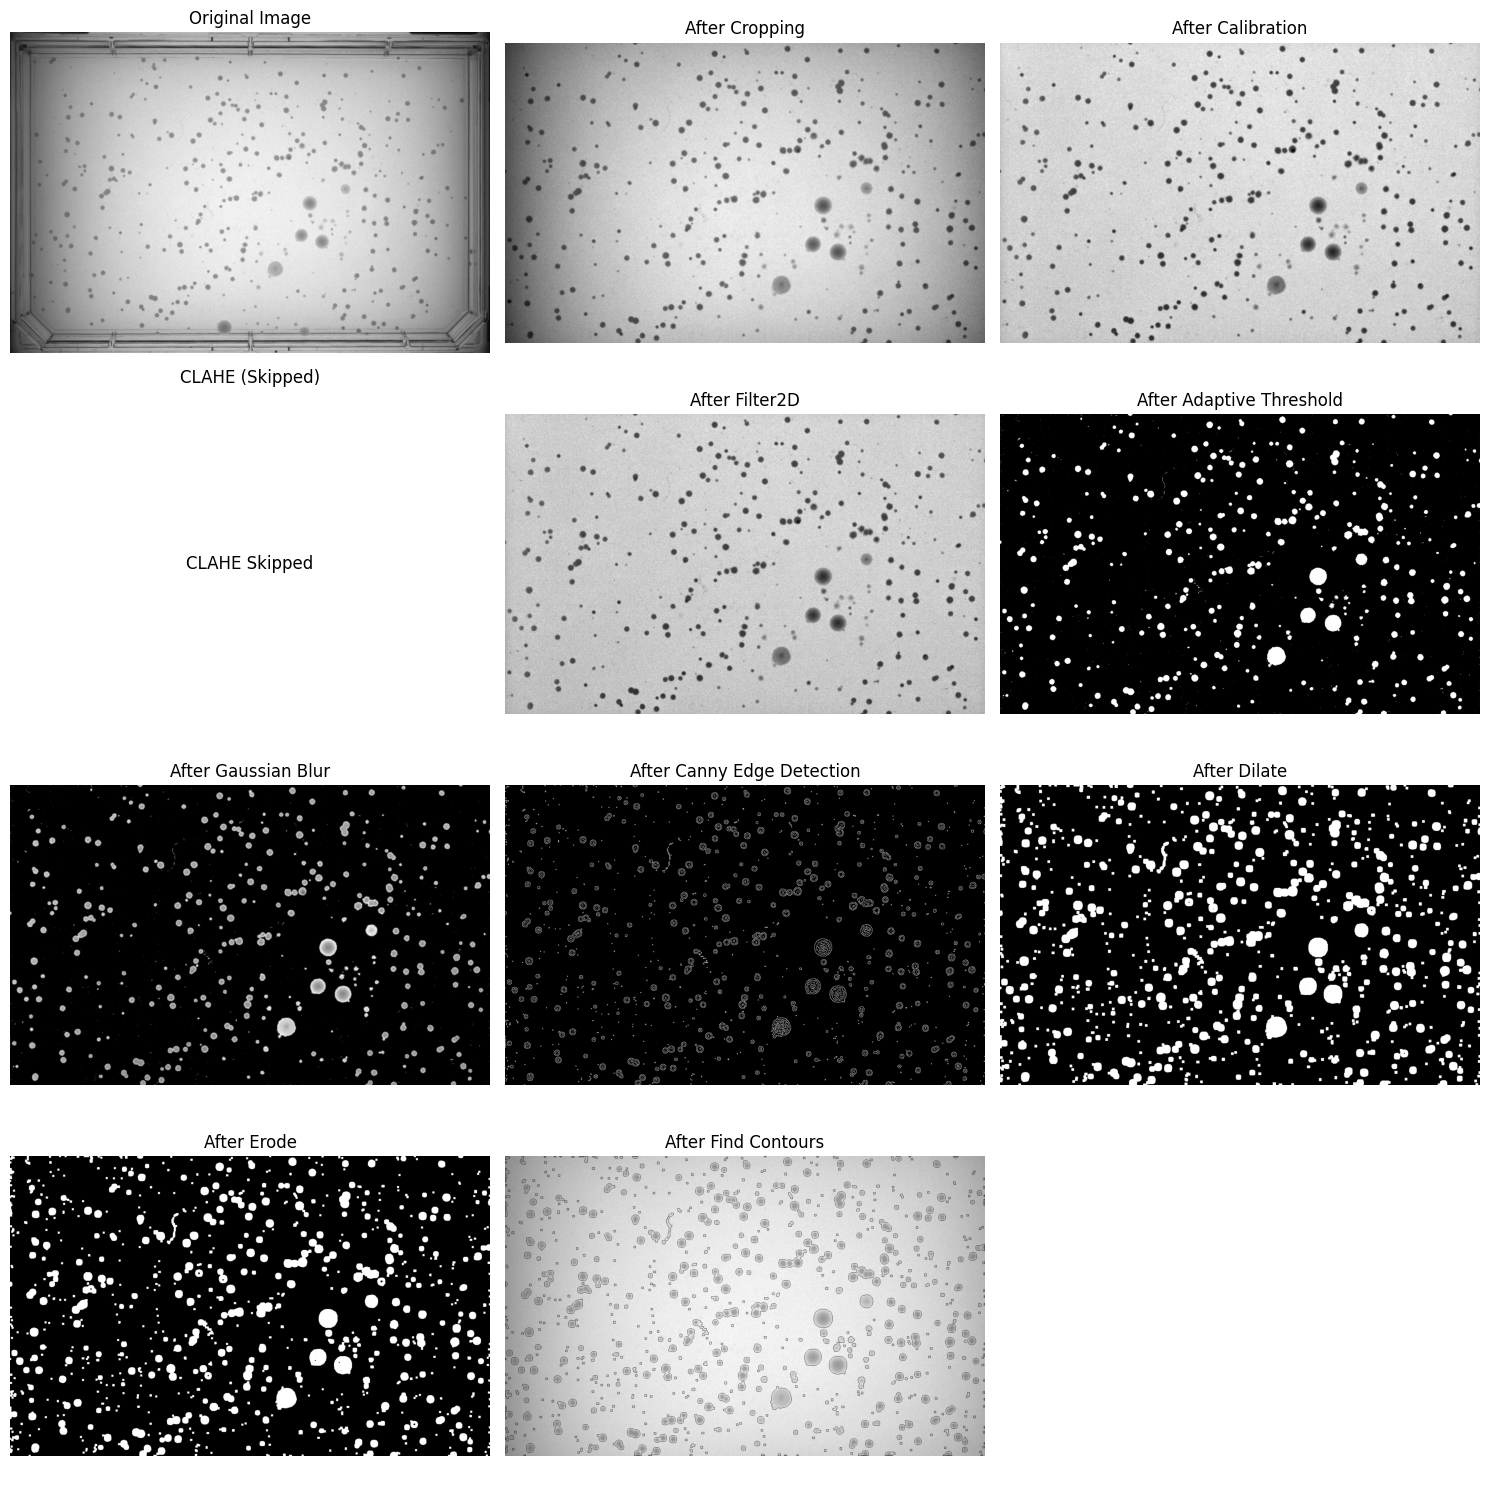

In [4]:
# Load calibration parameters from npz file
calib_file = config_path.parent.parent / "parameters" / "calib_parameter.npz"
calib_trans = np.load(calib_file)["image_trans_calib"]

# Create detector with hyperparameters from config
# Match contrast adjustment used by correct_image() function
detector = CAMIIColonyDetector(
    bg_gaussian_kernel=18,
    bg_threshold_block_size=config["bg_threshold_block_size"],
    bg_threshold_offset=config["bg_threshold_offset"],
    fg_gaussian_kernel=5,
    canny_upper_percentile=config["canny_upper_percentile"],
    clahe_clip_limit=2.0,
    clahe_tile_grid_size=(4, 4),
    calib_param=calib_trans,
    calib_contrast_alpha=config["calib_contrast_trans_alpha"],
    calib_contrast_beta=config["calib_contrast_trans_beta"],
    crop_x_min=config["crop_x_min"],
    crop_x_max=config["crop_x_max"],
    crop_y_min=config["crop_y_min"],
    crop_y_max=config["crop_y_max"],
    skip_clahe=True,
)

# Detect with diagnostic visualization (diagnose=True shows pipeline steps)
contours_raw, fig_diagnose, _ = detector.detect(image_trans_raw, diagnose=True)
fig_diagnose.show()

### 3.2. Using Streamlined `detect_colony()` Function

For production workflows, the `detect_colony()` function provides the same pipeline without diagnostic outputs. However, it requires **manual preprocessing** first.

**Preprocessing steps** (via `correct_image()`):
1. Correct for illumination non-uniformity (using calibration parameters from blank plates)
2. Adjust contrast: `calib_contrast_trans_alpha (5)`, `calib_contrast_trans_beta (-100)`
3. Crop plate borders: `crop_x_min (150)`, `crop_x_max (1750)`, `crop_y_min (150)`, `crop_y_max (1150)`

In [5]:
# Apply preprocessing (required for detect_colony function)
# Load calibration parameters from npz file

image_trans, image_epi = correct_image(
    config=config,
    image_trans_raw=image_trans_raw,
    image_epi_raw=image_epi_raw,
    calib_param=f"{config_path.parent.parent}/parameters/calib_parameter.npz",
    toss_red=False,
)

image_trans = np.clip(image_trans, 0, 255).astype(np.uint8)
image_epi = np.clip(image_epi, 0, 255).astype(np.uint8)

print(f"After preprocessing: {image_trans.shape}, dtype: {image_trans.dtype}")
print(
    f"Crop window: x=[{config['crop_x_min']}:{config['crop_x_max']}], y=[{config['crop_y_min']}:{config['crop_y_max']}]"
)

After preprocessing: (1000, 1600), dtype: uint8
Crop window: x=[150:1750], y=[150:1150]


In [6]:
# Use streamlined detect_colony function (no diagnostics)
contours_raw_2 = detect_colony(image_trans, config)

print(f"Detected {len(contours_raw_2)} raw contours")

Detected 670 raw contours


### 3.3. Verify Both Approaches Return Identical Results

Let's verify that both the class-based and function-based approaches produce the same contours.

In [7]:
# Check if both approaches return the same number of contours
print(f"CAMIIColonyDetector: {len(contours_raw)} contours")
print(f"detect_colony(): {len(contours_raw_2)} contours")
print(f"Same count: {len(contours_raw) == len(contours_raw_2)}")

# Check if contours are identical
if len(contours_raw) == len(contours_raw_2):
    all_match = True
    for i, (c1, c2) in enumerate(zip(contours_raw, contours_raw_2)):
        if not np.allclose(c1, c2, rtol=1e-5, atol=1e-8):
            all_match = False
            print(f"Contour {i} differs: max difference is {np.abs(c1 - c2).max():.6f}.")
            break
    
    if all_match:
        print("✓ All contours are identical!")
        print("Both approaches produce the same segmentation results.")
else:
    print("✗ Different number of contours detected.")
    print("The approaches may be using different parameters.")

CAMIIColonyDetector: 670 contours
detect_colony(): 670 contours
Same count: True
✓ All contours are identical!
Both approaches produce the same segmentation results.


## 4. Quality Control and Filtering

The `colony_qc()` function applies multi-stage filtering to remove false positives and handle edge cases.

**Filtering criteria and configs**:
1. **Size filtering**:
   - `min_size (400)`: Minimum colony area in pixels²
   - `max_size (2000000)`: Maximum colony area in pixels²
2. **Shape filtering**:
   - `min_circularity (0.2)`, `max_circularity (1.0)`: Circularity = 4πA/P²
   - `min_convexity (0.2)`, `max_convexity (1.0)`: Convexity = contour perimeter / convex hull perimeter
   - `min_inertia (0.2)`, `max_inertia (1.0)`: Inertia ratio = ratio of min/max eigenvalues of moment matrix
3. **Special rules**:
   - `small_size_area (80)`: Small colonies below this need high circularity
   - `small_size_circularity (0.85)`: Minimum circularity for small colonies
4. **Distance constraints**:
   - `min_dist (1)`: Minimum spacing between colony centers
   - `min_dist_pin (1)`: Minimum spacing between colony edges
5. **Border proximity**: `segment_bias (10)` + `filter_bias (20)`: Exclude colonies touching image borders
6. **Multi-colony segmentation**: For merged colonies (low circularity but appropriate size):
   - `circularity_threshold (0.85)`: Threshold below which segmentation is attempted
   - `circularity_threshold_very_bad (0.5)`: Very low circularity requiring segmentation
   - `area_segment_min (100)`, `area_segment_max (50000)`: Size range for segmentation
   - `random_walker_beta (2000)`: Penalty coefficient for random walker algorithm
   - Post-processing filters: `post_min_size (30)`, `post_min_circularity (0.5)`, `post_min_convexity (0.5)`, `post_min_inertia (0.5)`

**Returned objects**:
- `contours`: List of `np.ndarray` with shape `(n_points, 1, 2)` - colony boundaries
- `df_colonies`: Polars DataFrame with colony features (center_x, center_y, area, circularity, etc.)

In [8]:
# Apply quality control and filtering
contours_qc, df_colonies = colony_qc(image_trans, contours_raw, config)

# Add channel statistics from epi image (color features)
df_colonies = pl.concat(
    [
        df_colonies,
        pl.from_dict(
            _calc_contour_channel_mean_std(contours_qc, image_trans, image_epi)
        ),
    ],
    how="horizontal",
)

# Add plate metadata and adjust coordinates to original image space
df_colonies = _modify_output_object_colony_detection(df_colonies, plate, config)
contours_final = [
    cnt + np.array([config["crop_x_min"], config["crop_y_min"]]) for cnt in contours_qc
]

print(
    f"After QC: {len(contours_final)} colonies detected (from {len(contours_raw)} raw contours)"
)
print(f"Filtered out: {len(contours_raw) - len(contours_final)} contours")
print(f"\nDataFrame shape: {df_colonies.shape}")
print(f"\nColumns: {df_colonies.columns[:10]}...")  # Show first 10 columns

# Display statistics
df_colonies.select(["area", "circularity", "convexity", "inertia_ratio"]).describe()

670 colonies detected.

74 colonies passed initial filtering.

119 colonies need post-processing.

112 colonies passed post-processing.

186 colonies passed first filtering.

186 colonies passed second filtering.

After QC: 186 colonies detected (from 670 raw contours)
Filtered out: 484 contours

DataFrame shape: (186, 26)

Columns: ['colony_index', 'perim', 'hull_area', 'close_to_border', 'area', 'center_x', 'center_y', 'circularity', 'convexity', 'radius']...


statistic,area,circularity,convexity,inertia_ratio
str,f64,f64,f64,f64
"""count""",186.0,186.0,186.0,186.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",558.395161,0.822831,0.954021,0.997969
"""std""",423.669767,0.084289,0.040163,0.011312
"""min""",49.0,0.508589,0.75,0.871395
"""25%""",415.0,0.785398,0.946731,0.999568
"""50%""",514.0,0.853508,0.969473,0.999893
"""75%""",602.0,0.883464,0.978109,0.999949
"""max""",3848.0,0.917759,1.0,1.0


## 5. Visualize Segmentation Results

In [9]:
image_trans_raw.shape

(1296, 1938)

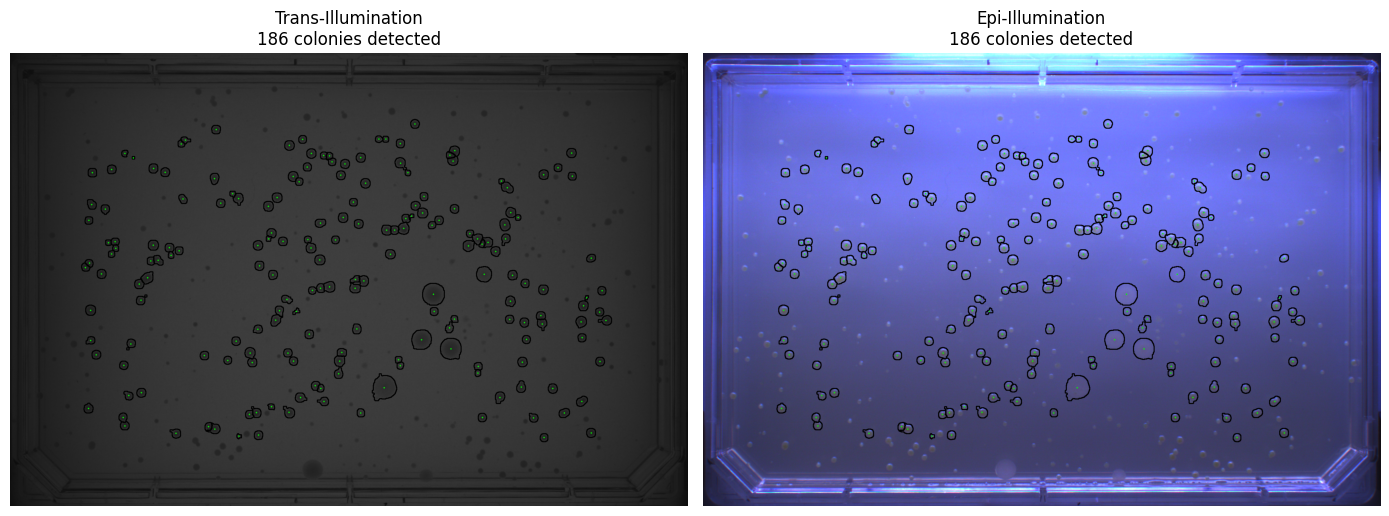

In [10]:
# Add contours to images using built-in utility
image_trans_annot = add_contours(
    image_trans_raw,
    contours_final,
    df_colonies[["center_x", "center_y"]].to_numpy(),
    contour_pixel=2,
    center_pixel=2,
)

image_epi_annot = add_contours(
    image_epi_raw,
    contours_final,
    df_colonies[["center_x", "center_y"]].to_numpy(),
    contour_pixel=2,
    center_pixel=2,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image_trans_annot.astype(np.uint8), cmap="gray")
axes[0].set_title(f"Trans-Illumination\n{len(contours_final)} colonies detected")
axes[0].axis("off")

axes[1].imshow(cv.cvtColor(image_epi_annot.astype(np.uint8), cv.COLOR_BGR2RGB))
axes[1].set_title(f"Epi-Illumination\n{len(contours_final)} colonies detected")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Summary

This notebook demonstrated camiira's colony segmentation pipeline using two approaches:

1. **`CAMIIColonyDetector` class**: Full pipeline with diagnostic visualization capabilities
2. **`detect_colony()` + `colony_qc()` functions**: Streamlined production workflow

**Key takeaways**:
- Trans-illumination provides superior contrast for boundary detection
- Epi-illumination adds phenotypic information (color, texture)  
- Quality control filters false positives using morphological criteria
- Multi-colony segmentation handles merged colonies

**Outputs**:
- `contours_final`: Colony boundary coordinates
- `df_colonies`: Polars DataFrame with morphological and color features

These outputs can be used for colony selection, alignment with other modalities (HSI, isolates), and phenotypic analysis.